# Análise experimental integrada — políticas de frota de drones

Este notebook reúne o catálogo das políticas, a metodologia, as tabelas e as visualizações em um único arquivo. Ele lê os resultados versionados que já estão no projeto e **não treina modelos, não altera os CSVs e não executa o simulador Java**.

Execute as células de cima para baixo a partir da pasta `rl/` ou da raiz do projeto. Os gráficos aparecem no próprio notebook; não são criadas pastas de resultados.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Localiza os dados tanto com cwd na raiz quanto dentro de rl/.
CANDIDATAS = [Path.cwd() / "rl" / "rl_resultados", Path.cwd() / "rl_resultados"]
DADOS = next((p for p in CANDIDATAS if p.exists()), None)
if DADOS is None:
    raise FileNotFoundError("Não encontrei rl_resultados. Rode o notebook na raiz do projeto ou em rl/.")
RL = DADOS.parent
print(f"Dados experimentais: {DADOS}")

EXECUCOES = {
    "DQN": DADOS / "experimentos/dqn/20261023_122550_dqn",
    "PPO": DADOS / "experimentos/ppo/20261023_122550_ppo",
    "QR-DQN": DADOS / "experimentos/qrdqn/20261023_122550_qrdqn",
    "MARL": DADOS / "experimentos/marl/20261023_122550_marl",
    "Decision Transformer": DADOS / "experimentos/dt/dt_reexec_20261023",
}
metricas = ["Entregas", "MMT_med(min)", "MMT_P95(min)", "SLA_ok(%)", "Q_fila_media",
            "Frota_media", "Aluguel_drone_h", "E_Consu(Wh)", "Entregas_por_Wh",
            "Decisao_CPU_med(ms)"]
rotulos = {
    "Entregas":"Entregas concluídas (n)", "MMT_med(min)":"MMT médio (min)",
    "MMT_P95(min)":"MMT P95 (min)", "SLA_ok(%)":"Entregas no SLA (%)",
    "Q_fila_media":"Fila média (pacotes)", "Frota_media":"Frota média (drones)",
    "Aluguel_drone_h":"Aluguel (drone·h)", "E_Consu(Wh)":"Energia estimada (Wh)",
    "Entregas_por_Wh":"Entregas por Wh", "Decisao_CPU_med(ms)":"CPU por decisão (ms)"
}
cores = {"DQN":"#4477AA", "PPO":"#66CCEE", "QR-DQN":"#228833", "MARL":"#CCBB44",
         "Decision Transformer":"#AA3377", "Busca Binária DT":"#EE7733", "Estático 60":"#999999"}

Dados experimentais: /home/callmepeh/Área de trabalho/PASID2/drone-delivery-sim-master-versao3(1)/drone-delivery-sim-master-versao3/rl/rl_resultados


## 1. Implementações e políticas identificadas

| Abordagem | Categoria e finalidade | Estado/entrada e ação | Observações |
|---|---|---|---|
| Busca Binária DT | Baseline de dimensionamento de frota do Digital Twin. A réplica Python aproxima M/M/n com Erlang-C e aplica reserva/devolução. | Demanda, alvo de MMT e capacidade; escolhe frota. | A lógica de busca do Java e sua réplica Python têm implementações distintas. |
| Estático 60 | Baseline sem aprendizado. | Mantém 60 drones. | Referência de capacidade fixa. |
| DQN | RL profundo off-policy, Q-learning para ações discretas. | Observação de 11 dimensões; delta de frota {-5,-3,-1,0,+1,+3,+5}. | Treino e avaliação em `train_rl.py` e `evaluate_rl.py`. |
| PPO | RL on-policy por otimização de política. | Mesmo ambiente e espaço de ações discreto. | Avaliação multi-seed disponível. |
| QR-DQN | RL off-policy que estima distribuição de retorno usando quantis. | Mesmo estado e ações do DQN; configuração com 50 quantis. | Estimar distribuição não significa otimizar automaticamente SLA ou CVaR. |
| MARL cooperativo | Dois learners Q com recompensa compartilhada. | Um controla delta de frota; outro a reserva de alugados (0/2/4/6). | Agentes controlam o sistema central, não drones individuais. |
| Decision Transformer | Aprendizado offline supervisionado de sequências. | Histórico estado/ação condicionado ao retorno; prevê ações. | Demonstrações derivam da Busca Binária DT; similaridade não prova descoberta de política melhor. |

O ambiente `drone_fleet_env.py` emula eventos discretos e foi confrontado com CSVs Java; não é uma integração ao vivo. Dynamic AD e regras de reserva são mecanismos do sistema, não algoritmos aprendidos. Não foram encontrados outros modelos aprendidos no código Python/Java inspecionado. Energia é estimada no ambiente; os resumos usados não incluem distância ou colisões.

## 2. Metodologia e carregamento

A comparação consolidada usa os resultados de 23/10/2026: cinco seeds de treinamento (42–46), cada modelo avaliado em 30 seeds de demanda comuns. As estatísticas abaixo agregam os **cinco modelos treinados**; portanto, DP significa variação entre treinos. Os baselines repetidos nos resumos por modelo são mantidos uma vez, sem contá-los como cinco réplicas independentes.

A comparação com o Digital Twin Java usa CSV agregado e é apresentada em seção separada. Não misturamos os protocolos.

In [2]:
# Lê os resumos por modelo. Os CSVs desta rodada usam ; e vírgula decimal.
partes = []
for algoritmo, pasta in EXECUCOES.items():
    arquivo = pasta / "resumo_por_modelo.csv"
    if not arquivo.exists():
        print(f"Resumo ausente: {arquivo}")
        continue
    frame = pd.read_csv(arquivo, sep=";", decimal=",")
    frame["Algoritmo"] = algoritmo
    partes.append(frame)
if not partes:
    raise FileNotFoundError("Nenhum resumo por modelo da rodada principal foi encontrado.")
dados = pd.concat(partes, ignore_index=True)
for coluna in metricas:
    if coluna in dados:
        dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

# Agrega uma linha por algoritmo/métrica; média, DP e faixa entre modelos.
linhas = []
for algoritmo, grupo in dados.groupby("Algoritmo", sort=False):
    grupo = grupo[grupo["Politica"].isin(["RL", "MARL", "DecisionTransformer"])]
    for metrica in metricas:
        if metrica not in grupo:
            continue
        valores = grupo[metrica].dropna()
        if len(valores):
            linhas.append({"Algoritmo":algoritmo, "Métrica":metrica, "N_treinos":len(valores),
                           "Média":valores.mean(), "DP_entre_treinos":valores.std(ddof=1),
                           "Mínimo":valores.min(), "Máximo":valores.max()})

# Baselines não aprendidos aparecem uma única vez. São medidas agregadas, sem DP entre treinos.
for politica, nome in [("BuscaBinariaDT", "Busca Binária DT"), ("Estatico60", "Estático 60")]:
    bloco = dados[dados["Politica"] == politica]
    if bloco.empty:
        continue
    registro = bloco.iloc[0]
    for metrica in metricas:
        if metrica in bloco and pd.notna(registro.get(metrica)):
            linhas.append({"Algoritmo":nome, "Métrica":metrica, "N_treinos":0,
                           "Média":registro[metrica], "DP_entre_treinos":np.nan,
                           "Mínimo":np.nan, "Máximo":np.nan})
resumo = pd.DataFrame(linhas)
print("Modelos carregados por algoritmo:")
display(dados.groupby("Algoritmo")["Seed_treino"].nunique().rename("N modelos").to_frame())

Modelos carregados por algoritmo:


,N modelos
Algoritmo,
DQN,5
Decision Transformer,5
MARL,5
PPO,5
QR-DQN,5


## 3. Tabela consolidada

MMT e fila menores costumam indicar melhor serviço; SLA maior é melhor. Frota, aluguel e latência representam custos distintos, então não há um vencedor único sem uma função de custo operacional definida. Os valores de baseline não têm DP porque são fornecidos como uma avaliação agregada.

In [3]:
ordem = ["Busca Binária DT", "DQN", "PPO", "QR-DQN", "MARL", "Decision Transformer", "Estático 60"]
pivot = resumo.pivot(index="Algoritmo", columns="Métrica", values="Média").reindex(ordem)
colunas_tabela = [c for c in ["MMT_med(min)", "MMT_P95(min)", "SLA_ok(%)", "Q_fila_media", "Frota_media", "Aluguel_drone_h", "Decisao_CPU_med(ms)"] if c in pivot]
tabela = pivot[colunas_tabela].rename(columns=rotulos).astype(object)
# Mostra média ± DP entre treinos somente para políticas aprendidas.
for alg in tabela.index:
    for metrica in colunas_tabela:
        dp = resumo.loc[(resumo.Algoritmo == alg) & (resumo.Métrica == metrica), "DP_entre_treinos"]
        if len(dp) and pd.notna(dp.iloc[0]):
            tabela.loc[alg, rotulos[metrica]] = f"{pivot.loc[alg, metrica]:.3f} ± {dp.iloc[0]:.3f}"
display(tabela)

Métrica,MMT médio (min),MMT P95 (min),Entregas no SLA (%),Fila média (pacotes),Frota média (drones),Aluguel (drone·h),CPU por decisão (ms)
Algoritmo,,,,,,,
Busca Binária DT,41.839842,96.625533,90.127,0.320278,68.073333,161.453333,0.04166
DQN,42.775 ± 0.816,97.019 ± 1.138,89.882 ± 0.448,1.785 ± 0.915,66.734 ± 0.626,134.682 ± 12.522,0.167 ± 0.002
PPO,42.660 ± 0.343,96.460 ± 0.700,89.921 ± 0.216,1.577 ± 0.368,67.185 ± 0.780,143.699 ± 15.613,0.300 ± 0.026
QR-DQN,42.915 ± 0.510,97.556 ± 1.035,89.833 ± 0.305,1.895 ± 0.428,66.440 ± 0.486,128.791 ± 9.733,0.290 ± 0.041
MARL,42.140 ± 0.315,96.294 ± 0.517,90.203 ± 0.178,1.061 ± 0.383,67.115 ± 0.281,142.289 ± 5.629,0.188 ± 0.005
Decision Transformer,41.774 ± 0.146,96.496 ± 0.528,90.180 ± 0.122,0.330 ± 0.012,68.011 ± 0.140,160.214 ± 2.788,2.065 ± 0.479
Estático 60,65.145871,132.468448,67.929667,27.475556,60.0,0.0,0.00105


### Diferenças descritivas frente à Busca Binária DT

Esta tabela subtrai médias agregadas. Ela **não** é um teste pareado; consulte os intervalos de confiança e as diferenças por seed já arquivadas nos diretórios de avaliação para inferência pareada.

In [4]:
base = pivot.loc["Busca Binária DT"]
linhas_delta = []
for algoritmo in [a for a in ordem if a not in ("Busca Binária DT", "Estático 60") and a in pivot.index]:
    for metrica in metricas:
        if metrica not in pivot or pd.isna(pivot.loc[algoritmo, metrica]) or pd.isna(base.get(metrica)):
            continue
        delta = pivot.loc[algoritmo, metrica] - base[metrica]
        linhas_delta.append({"Política":algoritmo, "Métrica":rotulos.get(metrica, metrica),
                             "Diferença absoluta":delta,
                             "Diferença relativa (%)":100*delta/abs(base[metrica]) if base[metrica] else np.nan})
diferencas = pd.DataFrame(linhas_delta)
display(diferencas.round(3))

,Política,Métrica,Diferença absoluta,Diferença relativa (%)
0,DQN,Entregas concluídas (n),0.580,0.042
1,DQN,MMT médio (min),0.935,2.235
2,DQN,MMT P95 (min),0.393,0.407
3,DQN,Entregas no SLA (%),-0.245,-0.272
4,DQN,Fila média (pacotes),1.464,457.181
5,DQN,Frota média (drones),-1.340,-1.968
6,DQN,Aluguel (drone·h),-26.771,-16.581
7,DQN,Energia estimada (Wh),-966.187,-0.860
8,DQN,Entregas por Wh,0.000,0.929
9,DQN,CPU por decisão (ms),0.126,301.922


## 4. Comparação visual: serviço e recursos

O primeiro painel mostra medidas complementares: MMT, SLA, frota, fila e drone-horas alugadas. Barras de erro são DP entre os cinco treinos; baselines aparecem sem barra. O gráfico SLA × frota destaca o compromisso entre qualidade de serviço e capacidade média.

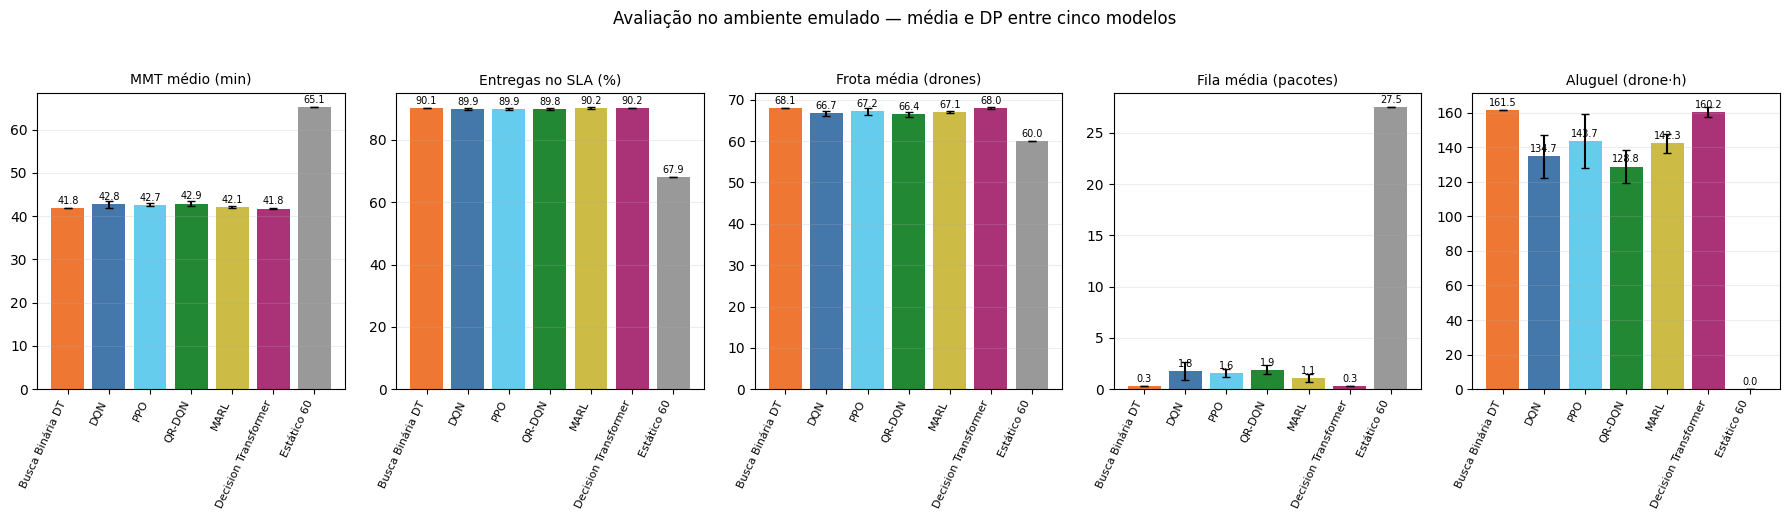

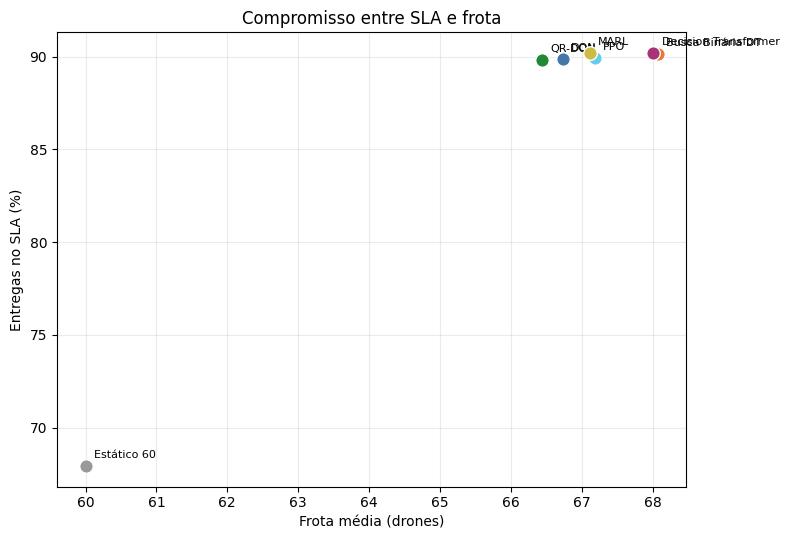

In [5]:
metricas_grafico = ["MMT_med(min)", "SLA_ok(%)", "Frota_media", "Q_fila_media", "Aluguel_drone_h"]
nomes = [n for n in ordem if n in pivot.index]
fig, axes = plt.subplots(1, len(metricas_grafico), figsize=(18, 5))
for ax, metrica in zip(axes, metricas_grafico):
    bloco = resumo[resumo.Métrica == metrica].set_index("Algoritmo").reindex(nomes).dropna(subset=["Média"])
    erros = bloco["DP_entre_treinos"].fillna(0)
    bars = ax.bar(range(len(bloco)), bloco.Média, yerr=erros, capsize=3,
                  color=[cores.get(n, "#777777") for n in bloco.index])
    ax.set_title(rotulos[metrica], fontsize=10)
    ax.set_xticks(range(len(bloco)), bloco.index, rotation=65, ha="right", fontsize=8)
    ax.grid(axis="y", alpha=.22)
    for bar, valor in zip(bars, bloco.Média):
        ax.annotate(f"{valor:.1f}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7)
fig.suptitle("Avaliação no ambiente emulado — média e DP entre cinco modelos", y=1.03)
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))
for algoritmo in nomes:
    x, y = pivot.loc[algoritmo, "Frota_media"], pivot.loc[algoritmo, "SLA_ok(%)"]
    ax.scatter(x, y, s=95, color=cores.get(algoritmo, "#777777"), edgecolor="white", zorder=3)
    ax.annotate(algoritmo, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set(xlabel=rotulos["Frota_media"], ylabel=rotulos["SLA_ok(%)"], title="Compromisso entre SLA e frota")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

### Leitura dos resultados

- Decision Transformer teve menor MMT médio pontual (41,774 min) entre os métodos aprendidos e SLA de 90,180%, muito próximo da Busca Binária DT (41,840 min; 90,127%). Os intervalos pareados registrados incluem zero para essas diferenças; isso não demonstra superioridade nem equivalência formal. A proximidade é coerente com o uso do baseline como demonstrador.
- MARL teve maior SLA pontual entre os métodos aprendidos (90,203%) e menor fila média (1,061), enquanto QR-DQN registrou menor frota (66,440) e menor aluguel (128,791 drone·h) entre os aprendidos. As prioridades levam a compromissos diferentes.
- Nenhuma política atingiu 95% de SLA. A frota dinâmica melhora SLA e fila frente à estática neste ambiente, mas usa capacidade e aluguel. Não se deve inferir causalidade fora das condições testadas.
- A latência medida do Decision Transformer (~2,1 ms) foi superior às demais; cronometragem depende de hardware e protocolo.
- Cinco seeds de treino são uma amostra limitada. O DP exibido quantifica variação entre treinos, não erro padrão dos episódios. O bootstrap arquivado é condicionado aos cinco checkpoints e não captura toda a incerteza de treinamento.

## 5. Aprendizado durante o treino DQN

A próxima figura usa `treino_dqn.csv`, um histórico de treino específico. Recompensa é o sinal otimizado pelo agente, não equivale diretamente a SLA, MMT ou custo operacional. Não há séries de treino comparáveis integradas para todos os algoritmos neste conjunto.

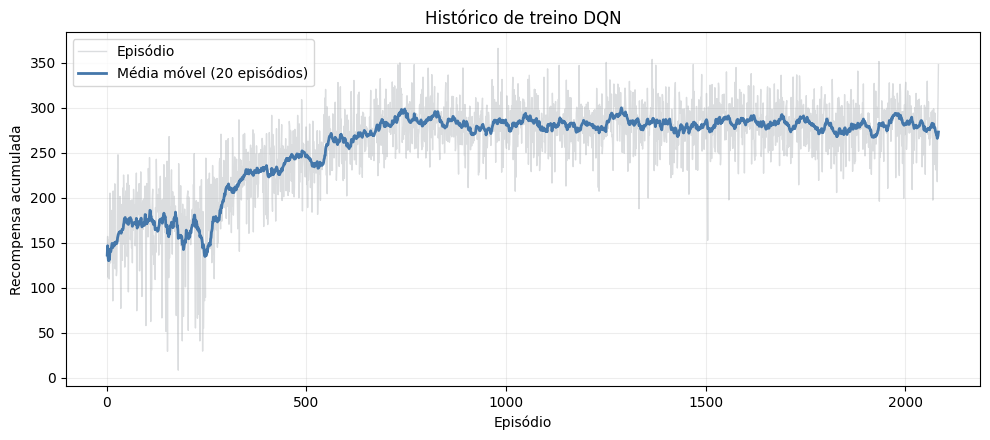

In [6]:
treino_path = DADOS / "treino_dqn.csv"
if treino_path.exists():
    treino = pd.read_csv(treino_path)
    treino["recompensa_total"] = pd.to_numeric(treino["recompensa_total"], errors="coerce")
    janela = max(1, min(20, len(treino)))
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(treino.episodio, treino.recompensa_total, color="#9AA0A6", alpha=.35, lw=1, label="Episódio")
    ax.plot(treino.episodio, treino.recompensa_total.rolling(janela, min_periods=1).mean(),
            color="#4477AA", lw=2, label=f"Média móvel ({janela} episódios)")
    ax.set(title="Histórico de treino DQN", xlabel="Episódio", ylabel="Recompensa acumulada")
    ax.grid(alpha=.22); ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Não há treino_dqn.csv nesta pasta de resultados.")

## 6. Resultados do Digital Twin Java — protocolo separado

Estes dados vêm do resumo dos experimentos de simulação Java e não devem ser comparados diretamente aos agentes RL do ambiente Python. Para séries temporais e estados de drones, consulte os notebooks de simulação existentes.

In [7]:
sim_path = RL.parent / "graficos_comparacao" / "resumo_comparacao.csv"
if sim_path.exists():
    simulacao = pd.read_csv(sim_path)
    colunas = [c for c in ["Configuração", "Entregas analisadas", "MMT médio por entrega (min)",
        "MMT P95 por entrega (min)", "SLA atendido por entrega (%)", "Fila média por snapshot",
        "Frota média ponderada no tempo", "Utilização média ponderada (%)"] if c in simulacao.columns]
    display(simulacao[colunas].round(3))
else:
    print(f"Resumo Java não encontrado: {sim_path}")

,,,,,,,,,,,,,,,,,
Estático;1357;64,14643777099852;60,42493508666667;130,66368272433334;225,18738317833333;69,12306558585114;419;30,87693441414886;25,104166666666668;108,0;1,1305554166666667;60,0;60,0;60,0;48,770990666736886;10,962289056641474;0,26672027662164094;81,28498444456149;60,0;0
Dinâmico;1354;61,699254118137624;57,29423225166667;125,93872132183333;303,71896452833334;73,70753323485968;356;26,292466765140325;24,079166666666666;105,0;1,1290279166666666;60,00000000000001;60,0;60,0;46,915510938848335;12,80177830700239;0,28271075414928476;78,19251823141389;60,0;0


## 7. Limitações e reprodutibilidade

- As conclusões multi-algoritmo referem-se ao simulador emulado e aos arquivos da rodada de 23/10/2026; a validação existente indica aproximação, não identidade perfeita com Java.
- Energia e entregas/Wh são estimativas do ambiente. Distância, colisões e violações físicas não constam dos resumos usados.
- O Decision Transformer imita dados do baseline; MARL controla o sistema central e não drones por região.
- A tabela pareada e intervalos de confiança existentes estão em `rl_resultados/experimentos/*/*/treino_seed_46/teste/`. Não recalculamos intervalos estatísticos a partir de resumos médios.
- Código de ambiente e recompensas: `drone_fleet_env.py`; políticas de referência: `dt_baseline.py`; treinamento: `train_rl.py`, `marl_train.py` e `train_decision_transformer.py`; avaliação: `evaluate_rl.py`, `experiment_rl.py` e `validate_env.py`.
- Este notebook lê os CSVs originais e mostra tudo inline. Para atualizar, reinicie o kernel e execute todas as células. Nenhum arquivo de resultado adicional é necessário.